### Bradley Terry Model: existence, uniqueness and optimization
This was a early experiment notebook and i intent to learn from the mistake i did, from this notebook.

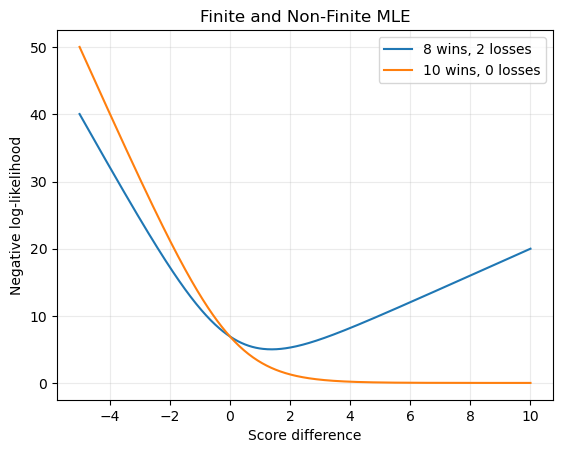

In [20]:
import numpy as np
import torch
import matplotlib.pyplot as plt 
from time import perf_counter
def sigmoid(x):
    return 1/(1+ np.exp(-x))
def two_item_nll(score_difference,wins,losses):
    probability=sigmoid(score_difference)
    return -(wins*np.log(probability)+losses*np.log(1-probability))
score_differences=np.linspace(-5,10,500)
finite_nll= [two_item_nll(score_difference,8,2) for score_difference in score_differences]
non_finite_nll= [two_item_nll(score_difference,10,0) for score_difference in score_differences]
plt.plot(score_differences,finite_nll,label="8 wins, 2 losses")
plt.plot(score_differences,non_finite_nll,label="10 wins, 0 losses")
plt.xlabel("Score difference")
plt.ylabel("Negative log-likelihood")
plt.title("Finite and Non-Finite MLE")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

Finite score difference: 1.38629436111989
Theoretical MLE: 1.3862943611198906
Non-finite score difference: 5.288614574466628


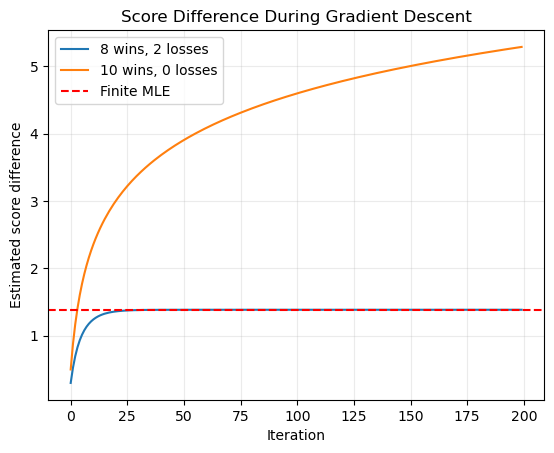

In [5]:
def two_item_gradient(score_difference,wins,losses):
    probability=sigmoid(score_difference)
    return (wins+losses)*probability-wins
def two_item_gradient_descent(wins,losses,learning_rate=0.1,iterations=200):
    score_difference=0.0
    score_history=[]
    for iteration in range(iterations):
        gradient=two_item_gradient(score_difference,wins,losses)
        score_difference=score_difference-learning_rate*gradient
        score_history.append(score_difference)
    return score_difference,score_history
finite_score,finite_history=two_item_gradient_descent(8,2)
non_finite_score,non_finite_history=two_item_gradient_descent(10,0)
print("Finite score difference:",finite_score)
print("Theoretical MLE:",np.log(8/2))
print("Non-finite score difference:",non_finite_score)
plt.plot(finite_history,label="8 wins, 2 losses")
plt.plot(non_finite_history,label="10 wins, 0 losses")
plt.axhline(np.log(8/2),color="red",linestyle="--",label="Finite MLE")
plt.xlabel("Iteration")
plt.ylabel("Estimated score difference")
plt.title("Score Difference During Gradient Descent")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [8]:
def bt_probability(item_i,item_j,scores):
    score_difference=scores[item_i]-scores[item_j]
    return sigmoid(score_difference)
scores=np.array([1.2,0.4,-0.3])
shifted_scores=scores+5
pairs=[(0,1),(0,2),(1,2)]
for item_i,item_j in pairs:
    original_probability=bt_probability(item_i,item_j,scores)
    shifted_probability=bt_probability(item_i,item_j,shifted_scores)
    print(
        "Pair:",item_i,item_j,
        "Original:",round(original_probability,4),
        "Shifted:",round(shifted_probability,4)
    )


Pair: 0 1 Original: 0.69 Shifted: 0.69
Pair: 0 2 Original: 0.8176 Shifted: 0.8176
Pair: 1 2 Original: 0.6682 Shifted: 0.6682


In [9]:
centered_scores=scores-np.mean(scores)
print("Original scores:",scores)
print("Centered scores:",centered_scores)
print("Mean:",np.mean(centered_scores))

Original scores: [ 1.2  0.4 -0.3]
Centered scores: [ 0.76666667 -0.03333333 -0.73333333]
Mean: -3.700743415417188e-17


Finite scores: [ 0.31401185  0.12828391 -0.44229576]
Non-finite scores: [ 4.90337813  0.         -4.90337813]


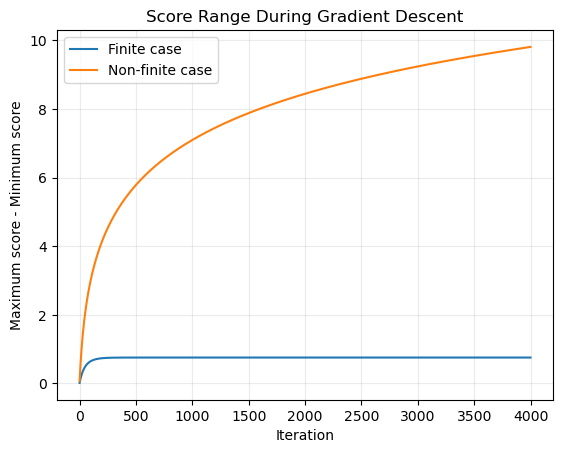

In [13]:
def negative_log_likelihood(scores,winners,losers):
    total_nll=0

    for winner,loser in zip(winners,losers):
        probability=bt_probability(winner,loser,scores)
        total_nll=total_nll-np.log(probability)

    return total_nll/len(winners)

def bt_gradient(scores,winners,losers):
    gradient=np.zeros_like(scores)

    for winner,loser in zip(winners,losers):
        probability=bt_probability(winner,loser,scores)
        gradient[winner]+=probability-1
        gradient[loser]+=1-probability

    return gradient/len(winners)

def estimate_bt_scores(number_of_items,winners,losers,iterations=4000):
    scores=np.zeros(number_of_items)
    score_range_history=[]

    for iteration in range(iterations):
        gradient=bt_gradient(scores,winners,losers)
        scores=scores-0.1*gradient
        scores=scores-np.mean(scores)
        score_range_history.append(np.max(scores)-np.min(scores))

    return scores,score_range_history
finite_winners=np.array([0,0,0,1,1,2])
finite_losers=np.array([1,1,2,0,2,0])
non_finite_winners=np.array([0,0,0,1,1,0])
non_finite_losers=np.array([1,1,2,2,2,2])
finite_scores,finite_range=estimate_bt_scores(
    3,
    finite_winners,
    finite_losers
)

non_finite_scores,non_finite_range=estimate_bt_scores(
    3,
    non_finite_winners,
    non_finite_losers
)

print("Finite scores:",finite_scores)
print("Non-finite scores:",non_finite_scores)
plt.plot(finite_range,label="Finite case")
plt.plot(non_finite_range,label="Non-finite case")
plt.xlabel("Iteration")
plt.ylabel("Maximum score - Minimum score")
plt.title("Score Range During Gradient Descent")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

Learning rate: 0.01 Iterations: 6989 Time: 0.22914 Final NLL: 0.662253
Learning rate: 0.05 Iterations: 1394 Time: 0.039329 Final NLL: 0.662253
Learning rate: 0.1 Iterations: 694 Time: 0.08249 Final NLL: 0.662253
Learning rate: 0.5 Iterations: 135 Time: 0.010965 Final NLL: 0.662253
Learning rate: 1.0 Iterations: 65 Time: 0.002119 Final NLL: 0.662253


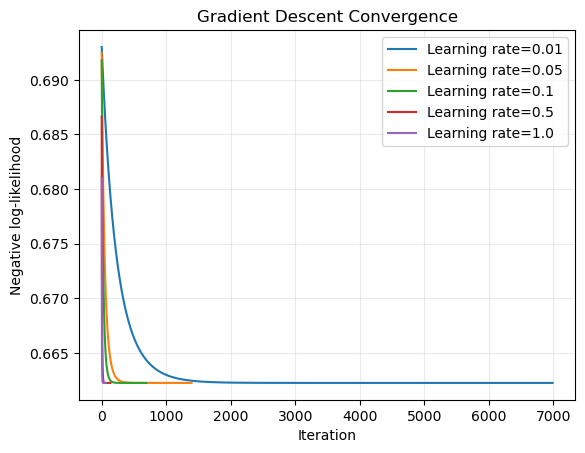

In [18]:
def gradient_descent_with_timing(
    number_of_items,
    winners,
    losers,
    learning_rate,
    max_iterations=10000,
    tolerance=1e-6):
    scores=np.zeros(number_of_items)
    nll_history=[]
    iterations_used=0
    start_time=perf_counter()

    for iteration in range(max_iterations):
        gradient=bt_gradient(scores,winners,losers)

        if np.linalg.norm(gradient)<tolerance:
            break

        scores=scores-learning_rate*gradient
        scores=scores-np.mean(scores)

        current_nll=negative_log_likelihood(scores,winners,losers)
        nll_history.append(current_nll)
        iterations_used+=1

    elapsed_time=perf_counter()-start_time

    return scores,nll_history,iterations_used,elapsed_time

learning_rates=[0.01,0.05,0.1,0.5,1.0]
convergence_results={}

for learning_rate in learning_rates:
    scores,nll_history,iterations_used,elapsed_time=gradient_descent_with_timing(
        3,
        finite_winners,
        finite_losers,
        learning_rate
    )

    convergence_results[learning_rate]=nll_history

    print(
        "Learning rate:",learning_rate,
        "Iterations:",iterations_used,
        "Time:",round(elapsed_time,6),
        "Final NLL:",round(nll_history[-1],6)
    )

for learning_rate,nll_history in convergence_results.items():
    plt.plot(nll_history,label=f"Learning rate={learning_rate}")

plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.title("Gradient Descent Convergence")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

PyTorch scores: [ 0.31401049  0.12828102 -0.44229151]
Iterations: 65
Time: 0.025641500018537045
Final NLL: 0.6622529671653852


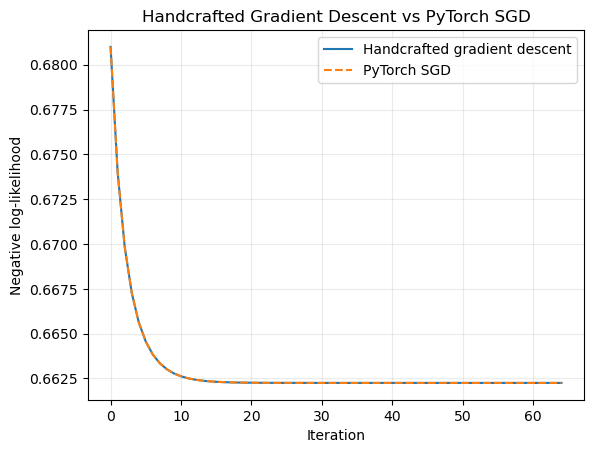

In [23]:
def pytorch_sgd(
    number_of_items,
    winners,
    losers,
    learning_rate=1.0,
    max_iterations=10000,
    tolerance=1e-6):

    winners_tensor=torch.tensor(winners,dtype=torch.long)
    losers_tensor=torch.tensor(losers,dtype=torch.long)

    scores=torch.zeros(
        number_of_items,
        dtype=torch.float64,
        requires_grad=True
    )

    optimizer=torch.optim.SGD([scores],lr=learning_rate)
    nll_history=[]
    iterations_used=0

    start_time=perf_counter()

    for iteration in range(max_iterations):
        optimizer.zero_grad()

        score_differences=scores[winners_tensor]-scores[losers_tensor]
        nll=torch.nn.functional.softplus(-score_differences).mean()

        nll.backward()

        if scores.grad.norm().item()<tolerance:
            break

        optimizer.step()

        with torch.no_grad():
            scores-=scores.mean()

            score_differences=scores[winners_tensor]-scores[losers_tensor]
            current_nll=torch.nn.functional.softplus(
                -score_differences
            ).mean().item()

        nll_history.append(current_nll)
        iterations_used+=1

    elapsed_time=perf_counter()-start_time

    return scores.detach().numpy(),nll_history,iterations_used,elapsed_time
pytorch_scores,pytorch_history,pytorch_iterations,pytorch_time=pytorch_sgd(
    3,
    finite_winners,
    finite_losers
)

print("PyTorch scores:",pytorch_scores)
print("Iterations:",pytorch_iterations)
print("Time:",pytorch_time)
print("Final NLL:",pytorch_history[-1])
plt.plot(
    convergence_results[1.0],
    label="Handcrafted gradient descent"
)

plt.plot(
    pytorch_history,
    linestyle="--",
    label="PyTorch SGD"
)

plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.title("Handcrafted Gradient Descent vs PyTorch SGD")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

Adam scores: [ 0.31401387  0.12828512 -0.44229899]
Iterations: 177
Time: 0.05839304195251316
Final NLL: 0.6622529671645406


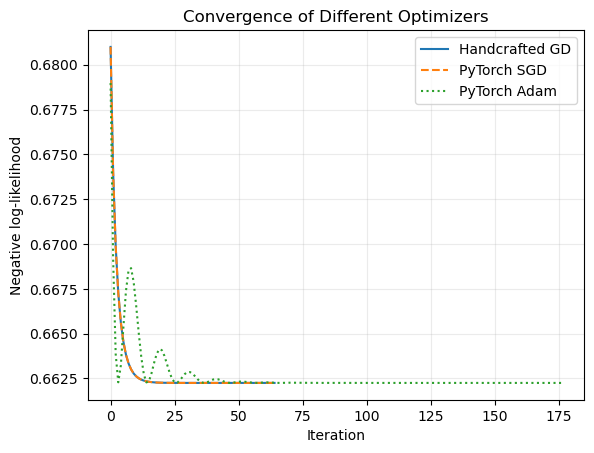

In [26]:
def pytorch_adam(
    number_of_items,
    winners,
    losers,
    learning_rate=0.1,
    max_iterations=10000,
    tolerance=1e-6):

    winners_tensor=torch.tensor(winners,dtype=torch.long)
    losers_tensor=torch.tensor(losers,dtype=torch.long)

    scores=torch.zeros(
        number_of_items,
        dtype=torch.float64,
        requires_grad=True
    )

    optimizer=torch.optim.Adam([scores],lr=learning_rate)
    nll_history=[]
    iterations_used=0

    start_time=perf_counter()

    for iteration in range(max_iterations):
        optimizer.zero_grad()

        score_differences=scores[winners_tensor]-scores[losers_tensor]
        nll=torch.nn.functional.softplus(-score_differences).mean()
        nll.backward()

        if scores.grad.norm().item()<tolerance:
            break

        optimizer.step()

        with torch.no_grad():
            scores-=scores.mean()

            score_differences=scores[winners_tensor]-scores[losers_tensor]
            current_nll=torch.nn.functional.softplus(
                -score_differences
            ).mean().item()

        nll_history.append(current_nll)
        iterations_used+=1

    elapsed_time=perf_counter()-start_time

    return scores.detach().numpy(),nll_history,iterations_used,elapsed_time
adam_scores,adam_history,adam_iterations,adam_time=pytorch_adam(
    3,
    finite_winners,
    finite_losers
)

print("Adam scores:",adam_scores)
print("Iterations:",adam_iterations)
print("Time:",adam_time)
print("Final NLL:",adam_history[-1])
plt.plot(convergence_results[1.0],label="Handcrafted GD")
plt.plot(pytorch_history,linestyle="--",label="PyTorch SGD")
plt.plot(adam_history,linestyle=":",label="PyTorch Adam")

plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.title("Convergence of Different Optimizers")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [28]:
SEED=20260831
rng=np.random.default_rng(SEED)
number_of_items=20
number_of_comparisons=5000
true_scores=np.linspace(1,-1,number_of_items)
true_scores=true_scores-np.mean(true_scores)
def generate_comparison_data(
    true_scores,
    number_of_comparisons,
    rng):

    winners=[]
    losers=[]
    number_of_items=len(true_scores)

    for comparison in range(number_of_comparisons):
        item_i,item_j=rng.choice(
            number_of_items,
            size=2,
            replace=False
        )

        probability_i_wins=bt_probability(
            item_i,
            item_j,
            true_scores
        )

        if rng.random()<probability_i_wins:
            winners.append(item_i)
            losers.append(item_j)
        else:
            winners.append(item_j)
            losers.append(item_i)

    return np.array(winners),np.array(losers)

In [ ]:
experiment_winners,experiment_losers=generate_comparison_data(
    true_scores,
    number_of_comparisons,
    rng
)
print("Number of items:",number_of_items)
print("Number of comparisons:",len(experiment_winners))
print("First five winners:",experiment_winners[:5])
print("First five losers:",experiment_losers[:5])

Number of items: 20
Number of comparisons: 5000
First five winners: [ 3 10  8  6 17]
First five losers: [ 6 12 19 13 11]


In [30]:
manual_scores,manual_history,manual_iterations,manual_time=gradient_descent_with_timing(
    number_of_items,
    experiment_winners,
    experiment_losers,
    learning_rate=1.0,
    max_iterations=5000
)

sgd_scores,sgd_history,sgd_iterations,sgd_time=pytorch_sgd(
    number_of_items,
    experiment_winners,
    experiment_losers,
    learning_rate=1.0,
    max_iterations=5000
)

adam_scores,adam_history,adam_iterations,adam_time=pytorch_adam(
    number_of_items,
    experiment_winners,
    experiment_losers,
    learning_rate=0.1,
    max_iterations=5000
)

Handcrafted GD: Iterations: 615 Time: 9.087 NLL: 0.605854 Error: 0.1032
PyTorch SGD: Iterations: 615 Time: 0.3855 NLL: 0.605854 Error: 0.1032
PyTorch Adam: Iterations: 201 Time: 0.0929 NLL: 0.605854 Error: 0.1032


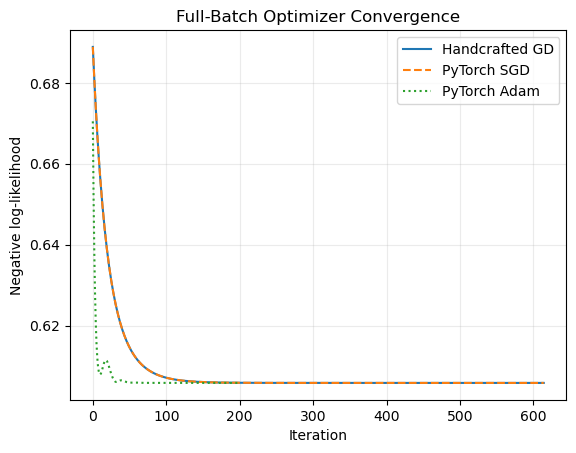

In [33]:
manual_error=np.sqrt(np.mean((manual_scores-true_scores)**2))
sgd_error=np.sqrt(np.mean((sgd_scores-true_scores)**2))
adam_error=np.sqrt(np.mean((adam_scores-true_scores)**2))
print(
    "Handcrafted GD:",
    "Iterations:",manual_iterations,
    "Time:",round(manual_time,4),
    "NLL:",round(manual_history[-1],6),
    "Error:",round(manual_error,4)
)

print(
    "PyTorch SGD:",
    "Iterations:",sgd_iterations,
    "Time:",round(sgd_time,4),
    "NLL:",round(sgd_history[-1],6),
    "Error:",round(sgd_error,4)
)

print(
    "PyTorch Adam:",
    "Iterations:",adam_iterations,
    "Time:",round(adam_time,4),
    "NLL:",round(adam_history[-1],6),
    "Error:",round(adam_error,4)
)
plt.plot(manual_history,label="Handcrafted GD")
plt.plot(sgd_history,linestyle="--",label="PyTorch SGD")
plt.plot(adam_history,linestyle=":",label="PyTorch Adam")
plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.title("Full-Batch Optimizer Convergence")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

Mini-batch Adam
Epochs: 100
Updates: 2000
Time: 0.5568
Final NLL: 0.605881
Recovery error: 0.1052


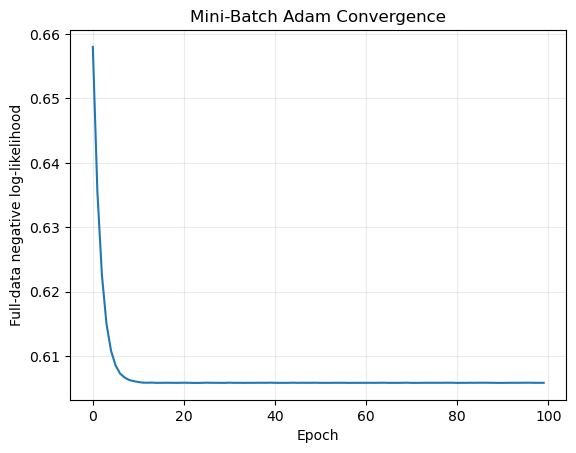

In [36]:
def pytorch_minibatch_adam(
    number_of_items,
    winners,
    losers,
    batch_size=256,
    learning_rate=0.01,
    number_of_epochs=100):

    torch.manual_seed(SEED)

    winners_tensor=torch.tensor(winners,dtype=torch.long)
    losers_tensor=torch.tensor(losers,dtype=torch.long)

    scores=torch.zeros(
        number_of_items,
        dtype=torch.float64,
        requires_grad=True
    )

    optimizer=torch.optim.Adam([scores],lr=learning_rate)
    nll_history=[]
    number_of_updates=0
    number_of_comparisons=len(winners)

    start_time=perf_counter()

    for epoch in range(number_of_epochs):
        shuffled_indices=torch.randperm(number_of_comparisons)

        for start_index in range(0,number_of_comparisons,batch_size):
            batch_indices=shuffled_indices[
                start_index:start_index+batch_size
            ]

            batch_winners=winners_tensor[batch_indices]
            batch_losers=losers_tensor[batch_indices]

            optimizer.zero_grad()

            score_differences=(
                scores[batch_winners]-scores[batch_losers]
            )

            batch_nll=torch.nn.functional.softplus(
                -score_differences
            ).mean()

            batch_nll.backward()
            optimizer.step()

            with torch.no_grad():
                scores-=scores.mean()

            number_of_updates+=1

        with torch.no_grad():
            full_score_differences=(
                scores[winners_tensor]-scores[losers_tensor]
            )

            full_nll=torch.nn.functional.softplus(
                -full_score_differences
            ).mean().item()

        nll_history.append(full_nll)

    elapsed_time=perf_counter()-start_time

    return (
        scores.detach().numpy(),
        nll_history,
        number_of_updates,
        elapsed_time
    )
minibatch_scores,minibatch_history,minibatch_updates,minibatch_time=pytorch_minibatch_adam(
    number_of_items,
    experiment_winners,
    experiment_losers
)

minibatch_error=np.sqrt(
    np.mean((minibatch_scores-true_scores)**2)
)

print("Mini-batch Adam")
print("Epochs:",len(minibatch_history))
print("Updates:",minibatch_updates)
print("Time:",round(minibatch_time,4))
print("Final NLL:",round(minibatch_history[-1],6))
print("Recovery error:",round(minibatch_error,4))
plt.plot(minibatch_history)

plt.xlabel("Epoch")
plt.ylabel("Full-data negative log-likelihood")
plt.title("Mini-Batch Adam Convergence")
plt.grid(alpha=0.25)
plt.show()

Batch size: 32 Updates: 2355 Time: 0.4358 NLL: 0.606023 Error: 0.1095
Batch size: 128 Updates: 600 Time: 0.3506 NLL: 0.605963 Error: 0.103
Batch size: 256 Updates: 300 Time: 0.0958 NLL: 0.605877 Error: 0.101
Batch size: 512 Updates: 150 Time: 0.0674 NLL: 0.606463 Error: 0.0942
Batch size: 1024 Updates: 75 Time: 0.0402 NLL: 0.613484 Error: 0.1845


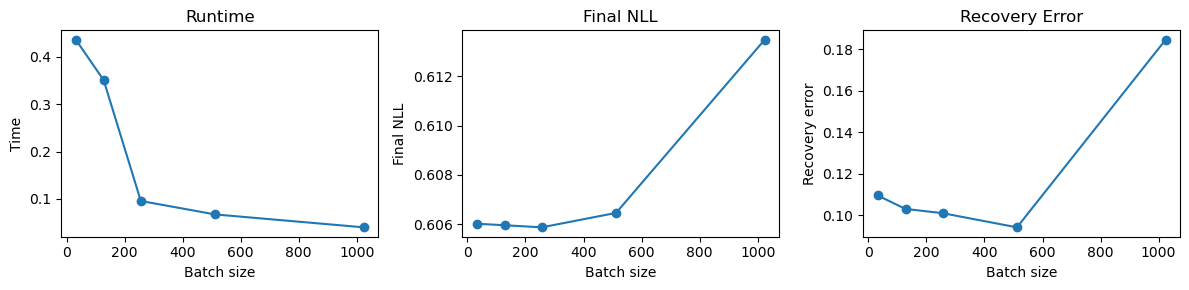

In [ ]:
batch_sizes=[32,128,256,512,1024]

batch_times=[]
batch_nlls=[]
batch_errors=[]
batch_updates=[]

for batch_size in batch_sizes:
    scores,nll_history,updates,elapsed_time=pytorch_minibatch_adam(
        number_of_items,
        experiment_winners,
        experiment_losers,
        batch_size=batch_size,
        learning_rate=0.01,
        number_of_epochs=15
    )

    error=np.sqrt(np.mean((scores-true_scores)**2))

    batch_times.append(elapsed_time)
    batch_nlls.append(nll_history[-1])
    batch_errors.append(error)
    batch_updates.append(updates)

    print(
        "Batch size:",batch_size,
        "Updates:",updates,
        "Time:",round(elapsed_time,4),
        "NLL:",round(nll_history[-1],6),
        "Error:",round(error,4)
    )
plt.figure(figsize=(12,3))
plt.subplot(1,3,1)
plt.plot(batch_sizes,batch_times,marker="o")
plt.xlabel("Batch size")
plt.ylabel("Time")
plt.title("Runtime")
plt.subplot(1,3,2)
plt.plot(batch_sizes,batch_nlls,marker="o")
plt.xlabel("Batch size")
plt.ylabel("Final NLL")
plt.title("Final NLL")

plt.subplot(1,3,3)
plt.plot(batch_sizes,batch_errors,marker="o")
plt.xlabel("Batch size")
plt.ylabel("Recovery error")
plt.title("Recovery Error")

plt.tight_layout()
plt.show()

Handcrafted GD Time: 9.087 NLL: 0.605854 Error: 0.1032 Updates: 615
PyTorch SGD Time: 0.3855 NLL: 0.605854 Error: 0.1032 Updates: 615
PyTorch Adam Time: 0.0929 NLL: 0.605854 Error: 0.1032 Updates: 201
Mini-batch Adam Time: 0.0958 NLL: 0.605877 Error: 0.101 Updates: 300


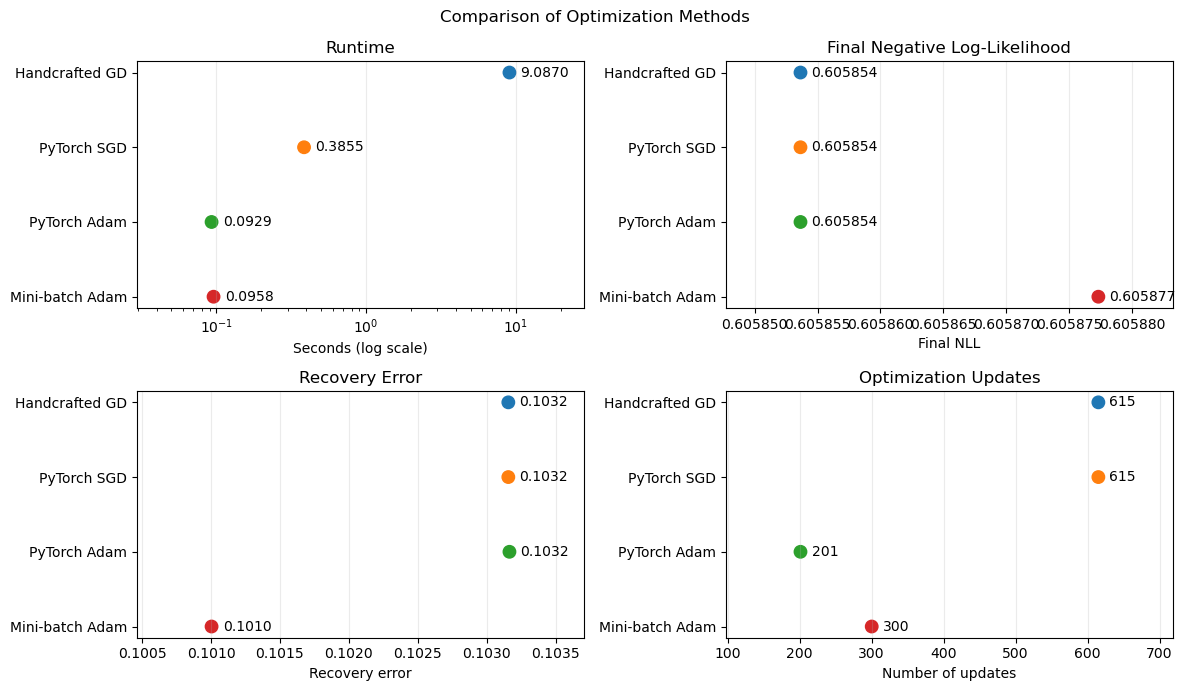

In [42]:
minibatch_index=batch_sizes.index(256)

methods=[
    "Handcrafted GD",
    "PyTorch SGD",
    "PyTorch Adam",
    "Mini-batch Adam"
]

times=[
    manual_time,
    sgd_time,
    adam_time,
    batch_times[minibatch_index]
]

final_nlls=[
    manual_history[-1],
    sgd_history[-1],
    adam_history[-1],
    batch_nlls[minibatch_index]
]

recovery_errors=[
    manual_error,
    sgd_error,
    adam_error,
    batch_errors[minibatch_index]
]

updates=[
    manual_iterations,
    sgd_iterations,
    adam_iterations,
    batch_updates[minibatch_index]
]
for index,method in enumerate(methods):
    print(
        method,
        "Time:",round(times[index],4),
        "NLL:",round(final_nlls[index],6),
        "Error:",round(recovery_errors[index],4),
        "Updates:",updates[index]
    )
methods=["Handcrafted GD","PyTorch SGD","PyTorch Adam","Mini-batch Adam"]
colors=["tab:blue","tab:orange","tab:green","tab:red"]
positions=np.arange(len(methods))

def add_values(axis,values,decimal_places):
    for position,value in zip(positions,values):
        axis.annotate(
            f"{value:.{decimal_places}f}",
            (value,position),
            xytext=(8,0),
            textcoords="offset points",
            va="center"
        )

fig,axes=plt.subplots(2,2,figsize=(12,7))

axes[0,0].scatter(times,positions,c=colors,s=80)
axes[0,0].set_xscale("log")
axes[0,0].set_title("Runtime")
axes[0,0].set_xlabel("Seconds (log scale)")
add_values(axes[0,0],times,4)

axes[0,1].scatter(final_nlls,positions,c=colors,s=80)
axes[0,1].set_title("Final Negative Log-Likelihood")
axes[0,1].set_xlabel("Final NLL")
axes[0,1].ticklabel_format(style="plain",axis="x",useOffset=False)
add_values(axes[0,1],final_nlls,6)

axes[1,0].scatter(recovery_errors,positions,c=colors,s=80)
axes[1,0].set_title("Recovery Error")
axes[1,0].set_xlabel("Recovery error")
add_values(axes[1,0],recovery_errors,4)

axes[1,1].scatter(updates,positions,c=colors,s=80)
axes[1,1].set_title("Optimization Updates")
axes[1,1].set_xlabel("Number of updates")
add_values(axes[1,1],updates,0)

for axis in axes.flat:
    axis.set_yticks(positions,methods)
    axis.invert_yaxis()
    axis.grid(axis="x",alpha=0.25)
    axis.margins(x=0.25)

plt.suptitle("Comparison of Optimization Methods")
plt.tight_layout()
plt.show()